# IMDB Sentiment Analysis: ML, MLP và LSTM

**Mục tiêu:** phân loại review phim thành Positive/Negative và so sánh Logistic Regression, SVM, MLP và LSTM.

> Trước khi chạy: đặt file Kaggle CSV vào thư mục `data/`. Notebook mặc định đọc `data/IMDB Dataset.csv`. Nếu tên file khác, sửa `DATA_PATH` ở cell tiếp theo.

In [6]:
from pathlib import Path
import re, time, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neural_network import MLPClassifier

SEED = 42
# Hỗ trợ chạy notebook từ thư mục gốc dự án hoặc từ notebooks/
CURRENT = Path.cwd()
PROJECT_ROOT = CURRENT.parent if CURRENT.name == "notebooks" else CURRENT
DATA_PATH = PROJECT_ROOT / "data" / "IMDB_Dataset.csv"  # sửa nếu tên file khác
MAX_TRAIN_SAMPLES = None  # đặt 10000 để chạy thử nhanh; None = dùng toàn bộ dữ liệu
MAX_TEST_SAMPLES = None
random.seed(SEED)
np.random.seed(SEED)

print("Notebook working directory:", CURRENT)
print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())


Notebook working directory: c:\visualstudiocode\NLP\LSTM\NLP-LSTM\notebooks
Project root: C:\visualstudiocode\NLP\LSTM\NLP-LSTM
Dataset path: C:\visualstudiocode\NLP\LSTM\NLP-LSTM\data\IMDB_Dataset.csv


## 1. Đọc và kiểm tra dữ liệu


In [7]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset: {DATA_PATH.resolve()}\n"
        "Hãy tạo thư mục data/ ở thư mục gốc dự án và đặt file CSV vào đó, "
        "hoặc sửa DATA_PATH cho đúng."
    )

df = pd.read_csv(DATA_PATH)
df.columns = [c.strip().lower() for c in df.columns]
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

# Tìm cột văn bản và cột nhãn
text_candidates = ["review", "text", "review_text", "content"]
label_candidates = ["sentiment", "label", "target", "polarity"]
text_col = next((c for c in text_candidates if c in df.columns), None)
label_col = next((c for c in label_candidates if c in df.columns), None)

if text_col is None or label_col is None:
    raise ValueError(
        "Không nhận diện được cột review/label. "
        f"Các cột hiện có: {df.columns.tolist()}. "
        "Hãy sửa text_candidates/label_candidates cho khớp dataset."
    )

df = df[[text_col, label_col]].dropna().copy()
df.columns = ["review", "sentiment"]
df["review"] = df["review"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

# Chuyển nhãn thành 0/1
label_map = {
    "negative": 0, "neg": 0, "0": 0,
    "positive": 1, "pos": 1, "1": 1
}
df["label"] = df["sentiment"].map(label_map)
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)
df = df[df["review"].str.len() > 0].reset_index(drop=True)

print("Số mẫu sau khi làm sạch:", len(df))
display(df["label"].map({0:"negative", 1:"positive"}).value_counts())

Shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Số mẫu sau khi làm sạch: 50000


label
positive    25000
negative    25000
Name: count, dtype: int64

## 2. Chia train/test

Giữ tập test riêng và dùng cùng một tập test cho mọi mô hình. `stratify` giữ tỷ lệ nhãn tương tự giữa hai tập.

In [8]:
if MAX_TRAIN_SAMPLES is not None and MAX_TRAIN_SAMPLES < len(df):
    # Lấy mẫu phân tầng để chạy thử nhanh; không dùng kết quả thử nghiệm làm kết quả cuối
    df, _ = train_test_split(
        df, train_size=MAX_TRAIN_SAMPLES, random_state=SEED, stratify=df["label"]
    )
    df = df.reset_index(drop=True)

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df["label"]
)
if MAX_TEST_SAMPLES is not None and MAX_TEST_SAMPLES < len(test_df):
    test_df, _ = train_test_split(
        test_df, train_size=MAX_TEST_SAMPLES, random_state=SEED, stratify=test_df["label"]
    )

X_train = train_df["review"].tolist()
y_train = train_df["label"].to_numpy()
X_test = test_df["review"].tolist()
y_test = test_df["label"].to_numpy()

print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print("Train label proportions:", pd.Series(y_train).value_counts(normalize=True).sort_index().to_dict())

Train: 40,000 | Test: 10,000
Train label proportions: {0: 0.5, 1: 0.5}


## 3. Hàm đánh giá chung

Accuracy đo tỷ lệ dự đoán đúng; Precision/Recall/F1 

In [9]:
results = []

def evaluate_model(name, y_true, y_pred, elapsed_seconds):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Prediction time (sec)": elapsed_seconds,
    }
    results.append(row)
    print(f"\n{name}")
    print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"], zero_division=0))
    return row

## 4. Baseline 1 — Logistic Regression với TF-IDF

TF-IDF chuyển review thành vector số dựa trên độ quan trọng của từ/ngữ.

In [10]:
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000, ngram_range=(1, 2), min_df=2,
        stop_words="english", sublinear_tf=True
    )),
    ("clf", LogisticRegression(max_iter=1000, C=2.0, random_state=SEED))
])

start = time.time()
lr_model.fit(X_train, y_train)
train_time_lr = time.time() - start
start = time.time()
pred_lr = lr_model.predict(X_test)
pred_time_lr = time.time() - start
evaluate_model("Logistic Regression (TF-IDF)", y_test, pred_lr, pred_time_lr)
print(f"Training time: {train_time_lr:.1f}s")


Logistic Regression (TF-IDF)
              precision    recall  f1-score   support

    Negative       0.92      0.90      0.91      5000
    Positive       0.90      0.92      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000

Training time: 20.2s


## 5. Baseline 2 — Linear SVM với TF-IDF

In [11]:
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000, ngram_range=(1, 2), min_df=2,
        stop_words="english", sublinear_tf=True
    )),
    ("clf", LinearSVC(C=1.0, random_state=SEED))
])

start = time.time()
svm_model.fit(X_train, y_train)
train_time_svm = time.time() - start
start = time.time()
pred_svm = svm_model.predict(X_test)
pred_time_svm = time.time() - start
evaluate_model("Linear SVM (TF-IDF)", y_test, pred_svm, pred_time_svm)
print(f"Training time: {train_time_svm:.1f}s")


Linear SVM (TF-IDF)
              precision    recall  f1-score   support

    Negative       0.91      0.90      0.91      5000
    Positive       0.90      0.92      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000

Training time: 19.9s


## 6. Baseline 3 — MLP (mạng neural cơ bản) với TF-IDF

MLP không có cơ chế ghi nhớ thứ tự chuỗi như LSTM. Mô hình này dùng cùng kiểu vector TF-IDF để so sánh.

In [12]:
mlp_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000, ngram_range=(1, 2), min_df=2,
        stop_words="english", sublinear_tf=True
    )),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(128,), activation="relu",
        solver="adam", alpha=1e-4, batch_size=128,
        learning_rate_init=1e-3, max_iter=15,
        early_stopping=True, validation_fraction=0.1,
        random_state=SEED, verbose=False
    ))
])

start = time.time()
mlp_model.fit(X_train, y_train)
train_time_mlp = time.time() - start
start = time.time()
pred_mlp = mlp_model.predict(X_test)
pred_time_mlp = time.time() - start
evaluate_model("MLP (TF-IDF)", y_test, pred_mlp, pred_time_mlp)
print(f"Training time: {train_time_mlp:.1f}s")


MLP (TF-IDF)
              precision    recall  f1-score   support

    Negative       0.91      0.91      0.91      5000
    Positive       0.91      0.91      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000

Training time: 419.5s


## 7. LSTM với PyTorch

LSTM nhận chuỗi token theo thứ tự. Để giới hạn thời gian và bộ nhớ, notebook giữ từ vựng phổ biến nhất và cắt/padding review về cùng độ dài.

In [13]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

MAX_VOCAB = 20000
MAX_LEN = 250
BATCH_SIZE = 128
EMBED_DIM = 128
HIDDEN_DIM = 128
EPOCHS = 5

def tokenize(text):
    return re.findall(r"[a-z]+|[0-9]+", text.lower())

# Tạo vocabulary chỉ từ tập train để tránh rò rỉ dữ liệu
from collections import Counter
counter = Counter()
for text in X_train:
    counter.update(tokenize(text))

PAD_IDX, UNK_IDX = 0, 1
vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode(text):
    ids = [vocab.get(tok, UNK_IDX) for tok in tokenize(text)[:MAX_LEN]]
    if not ids:
        ids = [UNK_IDX]
    ids = ids[:MAX_LEN]
    return ids + [PAD_IDX] * (MAX_LEN - len(ids))

class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.x = torch.tensor(np.array([encode(t) for t in texts]), dtype=torch.long)
        self.y = torch.tensor(np.asarray(labels), dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

train_loader = DataLoader(ReviewDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(ReviewDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        last_hidden = hidden[-1]
        return self.fc(self.dropout(last_hidden)).squeeze(1)

lstm_model = LSTMSentiment(len(vocab), EMBED_DIM, HIDDEN_DIM, PAD_IDX).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=1e-3)

def run_epoch(model, loader, training):
    model.train(training)
    total_loss, total, correct = 0.0, 0, 0
    all_labels, all_preds = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).long()
            total_loss += loss.item() * len(yb)
            total += len(yb)
            correct += (preds == yb.long()).sum().item()
            all_labels.extend(yb.detach().cpu().numpy().astype(int).tolist())
            all_preds.extend(preds.detach().cpu().numpy().tolist())
    return total_loss / total, correct / total, np.array(all_labels), np.array(all_preds)

history = []
start_train = time.time()
for epoch in range(EPOCHS):
    tr_loss, tr_acc, _, _ = run_epoch(lstm_model, train_loader, training=True)
    te_loss, te_acc, _, _ = run_epoch(lstm_model, test_loader, training=False)
    history.append({"epoch": epoch + 1, "train_loss": tr_loss, "train_accuracy": tr_acc,
                    "test_loss": te_loss, "test_accuracy": te_acc})
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss={tr_loss:.4f}, acc={tr_acc:.4f} "
          f"| test loss={te_loss:.4f}, acc={te_acc:.4f}")
train_time_lstm = time.time() - start_train

# Final evaluation
start = time.time()
_, _, y_lstm_true, pred_lstm = run_epoch(lstm_model, test_loader, training=False)
pred_time_lstm = time.time() - start
evaluate_model("LSTM (PyTorch)", y_lstm_true, pred_lstm, pred_time_lstm)
print(f"Training time: {train_time_lstm:.1f}s")

Device: cpu
Epoch 1/5 | train loss=0.6916, acc=0.5138 | test loss=0.6922, acc=0.5128
Epoch 2/5 | train loss=0.6817, acc=0.5450 | test loss=0.6884, acc=0.5089
Epoch 3/5 | train loss=0.6566, acc=0.6070 | test loss=0.6422, acc=0.6464
Epoch 4/5 | train loss=0.6086, acc=0.6917 | test loss=0.6113, acc=0.6952
Epoch 5/5 | train loss=0.5603, acc=0.7379 | test loss=0.5792, acc=0.7226

LSTM (PyTorch)
              precision    recall  f1-score   support

    Negative       0.68      0.84      0.75      5000
    Positive       0.79      0.61      0.69      5000

    accuracy                           0.72     10000
   macro avg       0.74      0.72      0.72     10000
weighted avg       0.74      0.72      0.72     10000

Training time: 1066.8s


## 8. So sánh kết quả

,Model,Accuracy,Precision,Recall,F1-score,Prediction time (sec)
0,Logistic Regression (TF-IDF),0.9092,0.9029,0.9170,0.9099,1.88
1,Linear SVM (TF-IDF),0.9078,0.9020,0.9150,0.9085,1.91
2,MLP (TF-IDF),0.9084,0.9107,0.9056,0.9081,1.77
3,LSTM (PyTorch),0.7226,0.7901,0.6062,0.6861,3.75


Đã lưu c:\visualstudiocode\NLP\LSTM\NLP-LSTM\results\comparison.csv


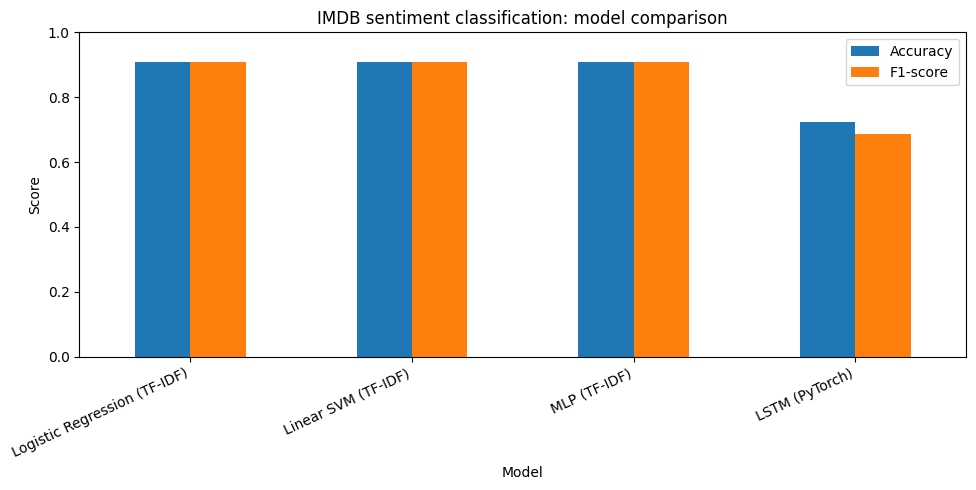

In [14]:
results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-score": "{:.4f}", "Prediction time (sec)": "{:.2f}"
}))

(PROJECT_ROOT / "results").mkdir(exist_ok=True)
results_df.to_csv(PROJECT_ROOT / "results" / "comparison.csv", index=False)
print("Đã lưu", PROJECT_ROOT / "results" / "comparison.csv")

ax = results_df.set_index("Model")[["Accuracy", "F1-score"]].plot(kind="bar", figsize=(10, 5))
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("IMDB sentiment classification: model comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "comparison.png", dpi=150)
plt.show()

## 9. Confusion matrix cho LSTM

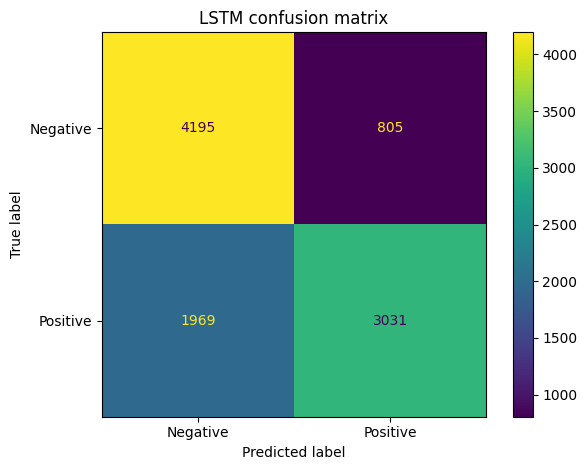

In [15]:
cm = confusion_matrix(y_lstm_true, pred_lstm)
disp = ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"])
disp.plot(values_format="d")
plt.title("LSTM confusion matrix")
plt.tight_layout()
plt.show()

## 10. Thử dự đoán một review mới

Thay ví dụ bằng câu tiếng Anh bất kỳ. Điểm gần 1 nghĩa là Positive, gần 0 nghĩa là Negative.

In [16]:
def predict_sentiment_lstm(review):
    lstm_model.eval()
    x = torch.tensor([encode(review)], dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        probability = torch.sigmoid(lstm_model(x)).item()
    label = "Positive" if probability >= 0.5 else "Negative"
    return {"sentiment": label, "positive_probability": round(probability, 4)}

predict_sentiment_lstm("The movie was surprisingly good and the acting was excellent.")

{'sentiment': 'Negative', 'positive_probability': 0.325}

## 11. Gợi ý viết phần nhận xét trong báo cáo

Sau khi chạy xong, dựa trên bảng kết quả thực tế để trả lời:
1. Mô hình nào có Accuracy và F1-score cao nhất?
2. Logistic Regression/SVM có ưu điểm gì về tốc độ và hiệu quả với TF-IDF?
3. LSTM xử lý thứ tự từ trong review khác MLP như thế nào?
4. Mô hình nào tốn thời gian huấn luyện nhất?
5. Các giới hạn: độ dài review bị cắt ở `MAX_LEN`, vocabulary giới hạn, số epoch và phần cứng.

Không kết luận LSTM tốt hơn các mô hình khác nếu kết quả thực nghiệm của bạn không cho thấy điều đó.